In [ ]:
# ==========================================================================
# PAF Project Group 6
# Golden Hour Fatality Triage Dataset
# ==========================================================================

In [ ]:
# Upload the Highway accidents data
from google.colab import files
uploaded = files.upload()

1. Upload the Highway accidents data


Saving highway_accidents.csv to highway_accidents.csv


In [ ]:
import pandas as pd
import numpy as np
import requests
import geopandas as gpd
import warnings
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [ ]:
# Step 1. Inspecting raw data, its dimensions and column names
df = pd.read_csv("highway_accidents.csv")
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Avaialble columns:")
print(df.columns.tolist())
print (df.head(3))

Dataset Shape: 150,000 rows x 23 columns
Avaialble columns:
['date', 'km', 'road_direction', 'roadway_type', 'area_type', 'latitude', 'longitude', 'time_of_day', 'highway_type', 'Uphill', 'Crossing', 'Curve', 'Downhill', 'Temporary_Detour', 'Roadworks', 'Road_Intersection', 'Bridge', 'Straight', 'Regulated_Uturn', 'Roundabout', 'Tunnel', 'Overpass', 'accident_classification']
         date    km  road_direction  roadway_type  area_type  latitude  \
0  2007-01-01  45.5             1.0           0.0        0.0       NaN   
1  2007-01-01  83.9             1.0           0.0        1.0       NaN   
2  2007-01-01  11.0             0.0           0.0        0.0       NaN   

   longitude  time_of_day  highway_type  Uphill  ...  Temporary_Detour  \
0        NaN            0           3.0     0.0  ...               0.0   
1        NaN            1           3.0     0.0  ...               0.0   
2        NaN            3           0.0     0.0  ...               0.0   

   Roadworks  Road_Intersec

In [ ]:
df["date"]=pd.to_datetime(df["date"])
df["year"]=df["date"].dt.year
df["month"]=df["date"].dt.month
df["day"]=df["date"].dt.day
df

,date,km,road_direction,roadway_type,area_type,latitude,longitude,time_of_day,highway_type,Uphill,...,Bridge,Straight,Regulated_Uturn,Roundabout,Tunnel,Overpass,accident_classification,year,month,day
0,2007-01-01,45.5,1.0,0.0,0.0,NaN,NaN,0,3.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0,2007,1,1
1,2007-01-01,83.9,1.0,0.0,1.0,NaN,NaN,1,3.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1,2007,1,1
2,2007-01-01,11.0,0.0,0.0,0.0,NaN,NaN,3,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0,2007,1,1
3,2007-01-01,180.0,1.0,2.0,1.0,NaN,NaN,0,4.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1,2007,1,1
4,2007-01-01,230.6,0.0,2.0,0.0,NaN,NaN,0,3.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0,2007,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-12-31,412.5,0.0,0.0,1.0,-29.810654,-51.496686,3,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1,2025,12,31
149996,2025-12-31,51.0,1.0,0.0,0.0,-8.137602,-35.333387,2,4.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1,2025,12,31
149997,2025-12-31,645.5,1.0,0.0,0.0,-25.829749,-49.116659,0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0,2025,12,31
149998,2025-12-31,125.7,1.0,2.0,0.0,-23.969566,-50.235536,1,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1,2025,12,31


In [ ]:
#Step 2: Problem definition

#When an emergency call arrives, the dispatcher must chose between the standart
# patrol, basic ambulance, an immidiate Advanced Life Support or helicopter.
# Therefore, we chose to develop a model that estimates the probability of the crash being fatal.
# Hence, first step analysing the variables, in particular the outcome variable.

print("Inspecting 'accident_classification' value counts:")
acc_counts = df["accident_classification"].value_counts(dropna=False)
acc_pcts = (
    df["accident_classification"].value_counts(normalize=True, dropna=False)
    * 100)
target_profile = pd.DataFrame(
    {"Count": acc_counts, "Percentage (%)": acc_pcts.round(2)})
target_profile

# According to Data Dictionary: 0 = No Injuries, 1 = Injuries, 2 = Fatalities

target_profile["Data Dictionary Meaning"] = [
    "Injuries (Class 1)",
    "No Injuries (Class 0)",
    "Fatalities (Class 2)",
]
print(target_profile)

Inspecting 'accident_classification' value counts:
                         Count  Percentage (%) Data Dictionary Meaning
accident_classification                                               
1                        71781           47.85      Injuries (Class 1)
0                        70997           47.33   No Injuries (Class 0)
2                         7222            4.81    Fatalities (Class 2)


In [ ]:
#Since Class 2 of accident_classification is our target, the decision is to isolate it
df["is_fatal"] = (df["accident_classification"] == 2).astype(int)

print(f"\nTarget 'is_fatal':")
print(
    f"  - Non-Fatal (0): {(df['is_fatal'] == 0).sum():,} crashes ({ (1 - df['is_fatal'].mean())*100:.2f}%)"
)
print(
    f"  - Fatal (1):     {(df['is_fatal'] == 1).sum():,} crashes ({df['is_fatal'].mean()*100:.2f}%)"
)


Target 'is_fatal':
  - Non-Fatal (0): 142,778 crashes (95.19%)
  - Fatal (1):     7,222 crashes (4.81%)


In [ ]:
#Step 3: Data quality check

missing = df.isnull().mean()*100
print(missing.round(2).sort_values(ascending=False))


longitude                  70.82
latitude                   70.82
road_direction              0.06
km                          0.00
date                        0.00
area_type                   0.00
roadway_type                0.00
time_of_day                 0.00
highway_type                0.00
Uphill                      0.00
Crossing                    0.00
Curve                       0.00
Downhill                    0.00
Temporary_Detour            0.00
Roadworks                   0.00
Road_Intersection           0.00
Bridge                      0.00
Straight                    0.00
Regulated_Uturn             0.00
Roundabout                  0.00
Tunnel                      0.00
Overpass                    0.00
accident_classification     0.00
year                        0.00
month                       0.00
day                         0.00
is_fatal                    0.00
dtype: float64


In [ ]:
#From the first look we can see that around 70.82% of data in longitude and latitude
#are missing, while the rest of the fields have very little or no missing values.
# Next step is to analyse the reson why this data is missing and whether there is
# a particular pattern.

In [ ]:
gps_table = (pd.crosstab(df["year"], df["latitude"].isnull(), normalize="index") * 100)
gps_table

latitude,False,True
year,,
2007,0.0,100.0
2008,0.0,100.0
2009,0.0,100.0
2010,0.0,100.0
2011,0.0,100.0
2012,0.0,100.0
2013,0.0,100.0
2014,0.0,100.0
2015,0.0,100.0


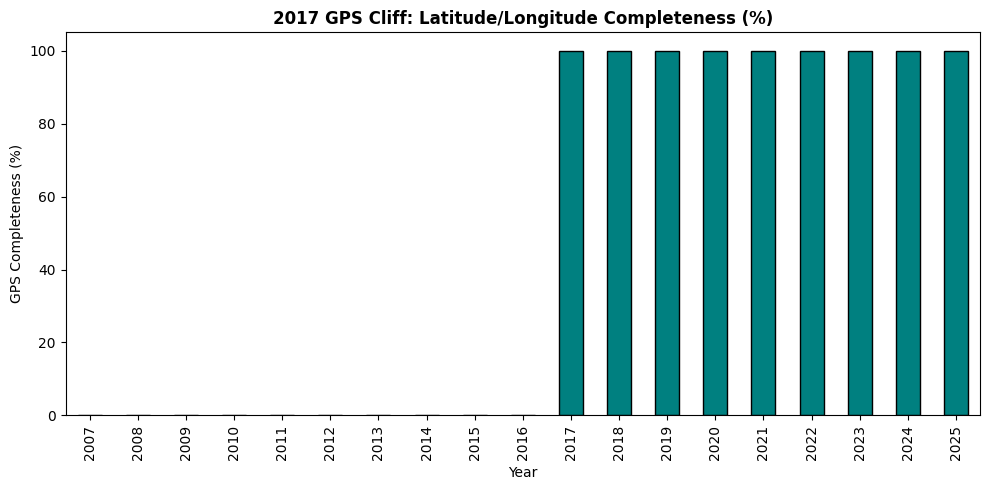

In [ ]:
plt.figure(figsize=(10, 5))
gps_table[False].plot(kind="bar", color="teal", edgecolor="black")

plt.title(
    "2017 GPS Cliff: Latitude/Longitude Completeness (%)",
    fontsize=12,
    fontweight="bold",
)
plt.ylabel("GPS Completeness (%)")
plt.xlabel("Year")

plt.tight_layout()
plt.show()

In [ ]:
# Further analysis uncovers that the GPS data is missing for 2007-2016.
# This is an important boundary that also shows that the GPS recordings only
# started from 2016.


In [ ]:
nulls_per_row = df.isnull().sum(axis=1)
corrupted_rows=df[nulls_per_row>10]
print(f"\nCorrupted Rows Found (>10 missing features): {len(corrupted_rows)}")


Corrupted Rows Found (>10 missing features): 1


In [ ]:
print("Corrupted Row Index:", corrupted_rows.index.tolist())
print("Sample Corrupted Row (Index 57163):",df.iloc[57163][
          ["date", "km", "Uphill", "Curve", "Bridge", "accident_classification"]
      ].to_dict(),)

Corrupted Row Index: [57163]
Sample Corrupted Row (Index 57163): {'date': Timestamp('2012-03-10 00:00:00'), 'km': 87.1, 'Uphill': nan, 'Curve': nan, 'Bridge': nan, 'accident_classification': 0}


In [ ]:
# Step 4: Analysing the  accident types per year to see if reporting changed over time


print("--- Year 2007 Accident Types (%) ---")
print(df[df["year"] == 2007]["accident_classification"].value_counts(
    normalize=True
) * 100)

print("\n--- Year 2025 Accident Types (%) ---")
print(df[df["year"] == 2025]["accident_classification"].value_counts(
    normalize=True
) * 100)

--- Year 2007 Accident Types (%) ---
accident_classification
0    59.456062
1    36.738658
2     3.805279
Name: proportion, dtype: float64

--- Year 2025 Accident Types (%) ---
accident_classification
1    77.542121
0    15.500496
2     6.957384
Name: proportion, dtype: float64


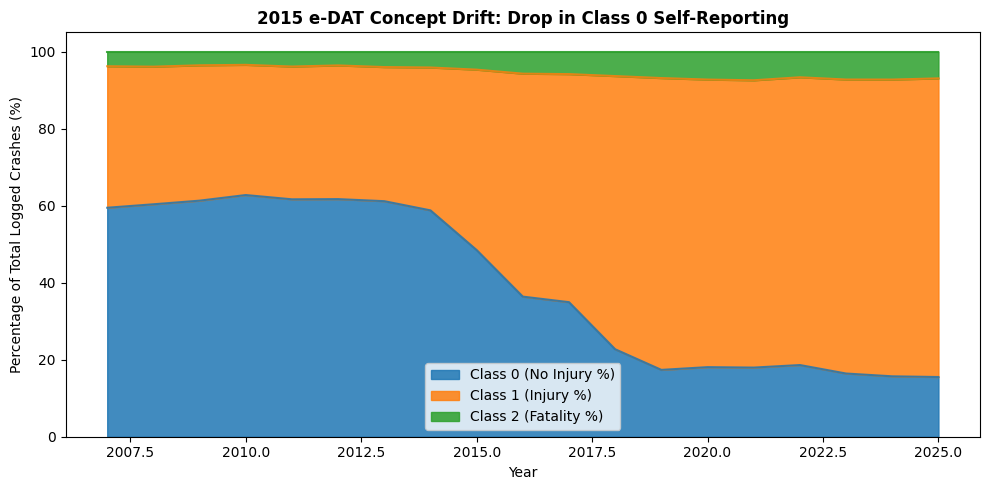

In [ ]:
drift_table = (
    pd.crosstab(df["year"], df["accident_classification"], normalize="index")
    * 100
)

drift_table.columns = [
    "Class 0 (No Injury %)",
    "Class 1 (Injury %)",
    "Class 2 (Fatality %)",]

plt.figure(figsize=(10, 5))
drift_table.plot(kind="area", stacked=True, alpha=0.85, ax=plt.gca())

plt.title(
    "2015 e-DAT Concept Drift: Drop in Class 0 Self-Reporting",
    fontsize=12,
    fontweight="bold",
)
plt.ylabel("Percentage of Total Logged Crashes (%)")
plt.xlabel("Year")

plt.tight_layout()
plt.show()

In [ ]:
#Comparing 2007 to 2025 reveals a  shift in recorded crash severity:
#Class 0 (no injuries) decreased from 59.5% to 15.5%
#Class 1 (injuries) increased from 36.7% to 77.5,
#Class 2 (fatalities) nearly doubled from 3.8% to 7.0%.

#The change in the results show a concept dirft.
#Around 2015, the introduction of online self-reporting (e-DAT) redirected minor
#non-injury fender-benders away from manual police logging.
#As a result, non-injury crashes "disappeared" from the official database,
#artificially inflating the proportion of severe crashes in modern years.

In [ ]:
# Step 5: Check fatality rates for key features one by one
# is_fatal: 1 = Fatal, 0 = Non-Fatal

print("--- Fatality Rate by Area Type (0 = Rural, 1 = Urban) ---")
area_summary = df.groupby("area_type")["is_fatal"].agg(["count", "mean"])
area_summary["fatality_rate_%"] = (area_summary["mean"] * 100).round(2)
print(area_summary)

print("\n--- Fatality Rate by Time of Day (0=Early Morning, 1=Morning, 2=Afternoon, 3=Night) ---")
time_summary = df.groupby("time_of_day")["is_fatal"].agg(["count", "mean"])
time_summary["fatality_rate_%"] = (time_summary["mean"] * 100).round(2)
print(time_summary)

print("\n--- Fatality Rate by Bridge (0 = No, 1 = Yes) ---")
bridge_summary = df.groupby("Bridge")["is_fatal"].agg(["count", "mean"])
bridge_summary["fatality_rate_%"] = (bridge_summary["mean"] * 100).round(2)
print(bridge_summary)

print("\n--- Fatality Rate by Downhill (0 = No, 1 = Yes) ---")
downhill_summary = df.groupby("Downhill")["is_fatal"].agg(["count", "mean"])
downhill_summary["fatality_rate_%"] = (downhill_summary["mean"] * 100).round(2)
print(downhill_summary)

--- Fatality Rate by Area Type (0 = Rural, 1 = Urban) ---
           count      mean  fatality_rate_%
area_type                                  
0.0        75673  0.064766             6.48
1.0        74326  0.031227             3.12

--- Fatality Rate by Time of Day (0=Early Morning, 1=Morning, 2=Afternoon, 3=Night) ---
             count      mean  fatality_rate_%
time_of_day                                  
0            48806  0.034381             3.44
1            16955  0.085226             8.52
2            42907  0.033118             3.31
3            41332  0.064792             6.48

--- Fatality Rate by Bridge (0 = No, 1 = Yes) ---
         count      mean  fatality_rate_%
Bridge                                   
0.0     149620  0.047995             4.80
1.0        379  0.108179            10.82

--- Fatality Rate by Downhill (0 = No, 1 = Yes) ---
           count      mean  fatality_rate_%
Downhill                                   
0.0       146518  0.047093             4.

In [ ]:
#Area Type (Rural vs. Urban): Rural highway crashes (6.48%) are more than twice
#as deadly as urban crashes (3.12%). This could be driven by higher vehicle speeds
#and longer emergency responder travel times.

#Time of Day: Morning hours (8.52%) and Night (6.48%) represent peak fatality periods,
#having higher risk than Early Morning (3.44%) or Afternoon (3.31%).

#Bridges (Bridge):  Bridge crashes seem to be relatively rare, but they are over twice as lethal (10.82%)
# compared to non-bridge crashes (4.80%).

#Downhill Segments (Downhill): Downhill nearly doubles crash fatality risk (9.25% vs. 4.71%),
#making it a strong physical predictor for real-time dispatch triage.

In [ ]:
# Step 5b: Road infrastructure sparsity check
infra_cols = [
    'Straight',
    'Curve',
    'Crossing',
    'Downhill',
    'Uphill',
    'Road_Intersection',
    'Roundabout',
    'Regulated_Uturn',
    'Roadworks',
    'Overpass',
    'Bridge',
    'Temporary_Detour',
    'Tunnel',
]

infra_summary = pd.DataFrame({
    'Total Crashes': df[infra_cols].sum().astype(int),
    'Prevalence (%)': (df[infra_cols].mean() * 100).round(2),
}).sort_values(by='Total Crashes', ascending=False)

print('--- Road Infrastructure Element Prevalence ---')
print(infra_summary)

--- Road Infrastructure Element Prevalence ---
                   Total Crashes  Prevalence (%)
Straight                  105958           70.64
Curve                      31319           20.88
Crossing                    7098            4.73
Downhill                    3481            2.32
Uphill                      2694            1.80
Road_Intersection           2625            1.75
Roundabout                  1009            0.67
Regulated_Uturn              858            0.57
Roadworks                    677            0.45
Overpass                     556            0.37
Bridge                       379            0.25
Temporary_Detour             144            0.10
Tunnel                        22            0.01


In [ ]:
# Step 6: Analysing the data leakage

all_columns = df.columns.tolist()
print(all_columns)

# Identify Target & Derived Target Columns
target_cols = ["accident_classification", "is_fatal"]

# Identify Predictor Candidates (Known at t=0)
# Road geometry, spatial markers, and temporal context are all known at call intake.
predictor_candidates = [col for col in all_columns if col not in target_cols]

#Data leakage results
print(f"Total Columns in Dataset: {len(all_columns)}")
print(f"Target Variables (Must be excluded from predictors): {target_cols}")
print(
    f"\nPredictor Features Available at t=0 Intake ({len(predictor_candidates)} columns):"
)
for col in predictor_candidates:
  print(f"  [SAFE] {col}")

print(
    "\nAudit Verdict: No post-crash operational fields (e.g., victim counts or damage scores) exist in this dataset."
)
print(
    "All predictor features reflect pre-existing road conditions or time context available at t=0."
)

['date', 'km', 'road_direction', 'roadway_type', 'area_type', 'latitude', 'longitude', 'time_of_day', 'highway_type', 'Uphill', 'Crossing', 'Curve', 'Downhill', 'Temporary_Detour', 'Roadworks', 'Road_Intersection', 'Bridge', 'Straight', 'Regulated_Uturn', 'Roundabout', 'Tunnel', 'Overpass', 'accident_classification', 'year', 'month', 'day', 'is_fatal']
Total Columns in Dataset: 27
Target Variables (Must be excluded from predictors): ['accident_classification', 'is_fatal']

Predictor Features Available at t=0 Intake (25 columns):
  [SAFE] date
  [SAFE] km
  [SAFE] road_direction
  [SAFE] roadway_type
  [SAFE] area_type
  [SAFE] latitude
  [SAFE] longitude
  [SAFE] time_of_day
  [SAFE] highway_type
  [SAFE] Uphill
  [SAFE] Crossing
  [SAFE] Curve
  [SAFE] Downhill
  [SAFE] Temporary_Detour
  [SAFE] Roadworks
  [SAFE] Road_Intersection
  [SAFE] Bridge
  [SAFE] Straight
  [SAFE] Regulated_Uturn
  [SAFE] Roundabout
  [SAFE] Tunnel
  [SAFE] Overpass
  [SAFE] year
  [SAFE] month
  [SAFE] day
